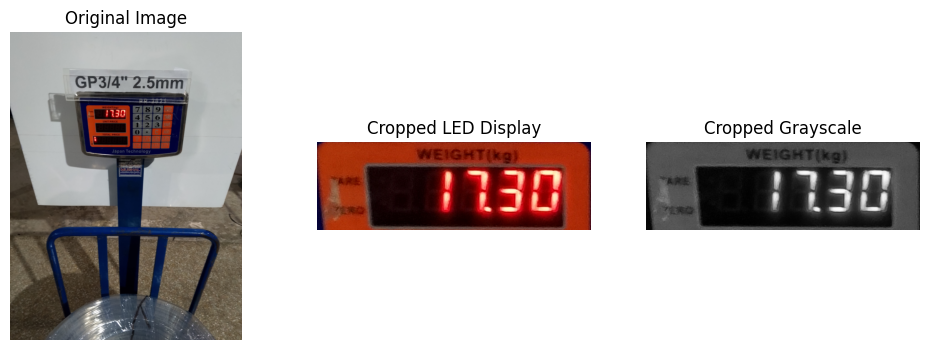

Detected weight: weightik2)138


In [5]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import easyocr
# Load image
image_path = r"IMG_20250909_195101_981.jpg"
image = cv2.imread(image_path)
image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

# Convert to HSV for color detection
hsv = cv2.cvtColor(image, cv2.COLOR_BGR2HSV)

# Define red color range
lower_red1 = np.array([0, 100, 100])
upper_red1 = np.array([10, 255, 255])
lower_red2 = np.array([160, 100, 100])
upper_red2 = np.array([180, 255, 255])

# Create mask for red areas
mask1 = cv2.inRange(hsv, lower_red1, upper_red1)
mask2 = cv2.inRange(hsv, lower_red2, upper_red2)
mask = cv2.bitwise_or(mask1, mask2)

# Optional: clean up mask
mask = cv2.morphologyEx(mask, cv2.MORPH_CLOSE, np.ones((5,5), np.uint8))
mask = cv2.morphologyEx(mask, cv2.MORPH_OPEN, np.ones((3,3), np.uint8))

# Find contours in mask
contours, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
contours = sorted(contours, key=cv2.contourArea, reverse=True)

if contours:
    x, y, w, h = cv2.boundingRect(contours[0])

    # Crop only top 34% of the detected bounding box
    new_h = max(1, int(h * 0.34))
    cropped = image_rgb[y:y+new_h, x:x+w]

    # Convert cropped image to grayscale
    cropped_gray = cv2.cvtColor(cropped, cv2.COLOR_RGB2GRAY)

    # Show results
    plt.figure(figsize=(12, 4))
    plt.subplot(1, 3, 1)
    plt.imshow(image_rgb)
    plt.title("Original Image")
    plt.axis('off')

    plt.subplot(1, 3, 2)
    plt.imshow(cropped)
    plt.title("Cropped LED Display")
    plt.axis('off')

    plt.subplot(1, 3, 3)
    plt.imshow(cropped_gray, cmap='gray')
    plt.title("Cropped Grayscale")
    plt.axis('off')

    plt.show()


else:
    print("No red LED display detected!")

reader = easyocr.Reader(['en'])
result = reader.readtext(cropped_gray)
weight = ''.join([res[1] for res in result])
print("Detected weight:", weight)


In [6]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# =========================================================
# 1️⃣ INPUT IMAGE
# =========================================================
image_path = r"IMG_20250909_194615_329.jpg"

# Read image
img = cv2.imread(image_path)
if img is None:
    raise SystemExit("❌ Image not found!")

# Convert to grayscale
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

# =========================================================
# 2️⃣ IMPROVED PREPROCESSING
# =========================================================
# Apply Gaussian blur to reduce noise
blur = cv2.GaussianBlur(gray, (5, 5), 0)

# Try multiple thresholding methods
# Method 1: Adaptive threshold
thresh1 = cv2.adaptiveThreshold(
    blur, 255, cv2.ADAPTIVE_THRESH_MEAN_C, cv2.THRESH_BINARY_INV, 35, 15
)

# Method 2: Otsu's threshold
_, thresh2 = cv2.threshold(blur, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)

# Method 3: Simple threshold (adjust value as needed)
_, thresh3 = cv2.threshold(blur, 100, 255, cv2.THRESH_BINARY_INV)

# Clean noise
kernel = np.ones((2, 2), np.uint8)
thresh1 = cv2.morphologyEx(thresh1, cv2.MORPH_OPEN, kernel)
thresh2 = cv2.morphologyEx(thresh2, cv2.MORPH_OPEN, kernel)
thresh3 = cv2.morphologyEx(thresh3, cv2.MORPH_OPEN, kernel)

# =========================================================
# 3️⃣ IMPROVED CONTOUR DETECTION
# =========================================================
def find_digit_contours(thresh_img, method_name):
    contours, _ = cv2.findContours(thresh_img, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

    digit_contours = []
    for c in contours:
        x, y, w, h = cv2.boundingRect(c)
        area = cv2.contourArea(c)

        # More flexible criteria
        aspect_ratio = h / float(w) if w > 0 else 0
        area_ratio = area / (w * h) if (w * h) > 0 else 0

        # Relaxed constraints - adjust based on your image
        if (0.8 < aspect_ratio < 8.0 and  # Wider aspect ratio range
            10 < h < 300 and              # More flexible height
            5 < w < 150 and               # More flexible width
            area > 50):                   # Minimum area
            digit_contours.append((x, y, w, h))

    # Sort contours left to right
    digit_contours = sorted(digit_contours, key=lambda x: x[0])
    print(f"✅ {method_name}: Found {len(digit_contours)} digit-like areas")

    return digit_contours

# Try all thresholding methods
contours1 = find_digit_contours(thresh1, "Adaptive Threshold")
contours2 = find_digit_contours(thresh2, "Otsu Threshold")
contours3 = find_digit_contours(thresh3, "Simple Threshold")

# Use the method that found the most contours
all_contours = [contours1, contours2, contours3]
best_contours = max(all_contours, key=len)
digit_contours = best_contours

# =========================================================
# 4️⃣ DEBUG VISUALIZATION
# =========================================================
plt.figure(figsize=(16, 12))

# Original image
plt.subplot(2, 3, 1)
plt.title("Original Image")
plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.axis('off')

# Grayscale
plt.subplot(2, 3, 2)
plt.title("Grayscale")
plt.imshow(gray, cmap='gray')
plt.axis('off')

# Different thresholding methods
plt.subplot(2, 3, 3)
plt.title("Adaptive Threshold")
plt.imshow(thresh1, cmap='gray')
plt.axis('off')

plt.subplot(2, 3, 4)
plt.title("Otsu Threshold")
plt.imshow(thresh2, cmap='gray')
plt.axis('off')

plt.subplot(2, 3, 5)
plt.title("Simple Threshold")
plt.imshow(thresh3, cmap='gray')
plt.axis('off')

# Final result with bounding boxes
plt.subplot(2, 3, 6)
plt.title(f"Detected Digits: {len(digit_contours)}")
result_img = img.copy()
for (x, y, w, h) in digit_contours:
    cv2.rectangle(result_img, (x, y), (x + w, y + h), (0, 255, 0), 2)
    # Add contour index
    cv2.putText(result_img, f"{x},{y}", (x, y-5),
                cv2.FONT_HERSHEY_SIMPLEX, 0.4, (255, 0, 0), 1)
plt.imshow(cv2.cvtColor(result_img, cv2.COLOR_BGR2RGB))
plt.axis('off')

plt.tight_layout()
plt.show()

# =========================================================
# 5️⃣ CONTOUR ANALYSIS
# =========================================================
print(f"\n📊 Contour Analysis:")
for i, (x, y, w, h) in enumerate(digit_contours):
    area = w * h
    aspect_ratio = h / w
    print(f"Contour {i}: Position=({x},{y}), Size=({w}x{h}), "
          f"Area={area}, Aspect Ratio={aspect_ratio:.2f}")pip install easyocr

SyntaxError: invalid syntax (ipython-input-1478170946.py, line 136)

✅ Found 0 digit-like areas


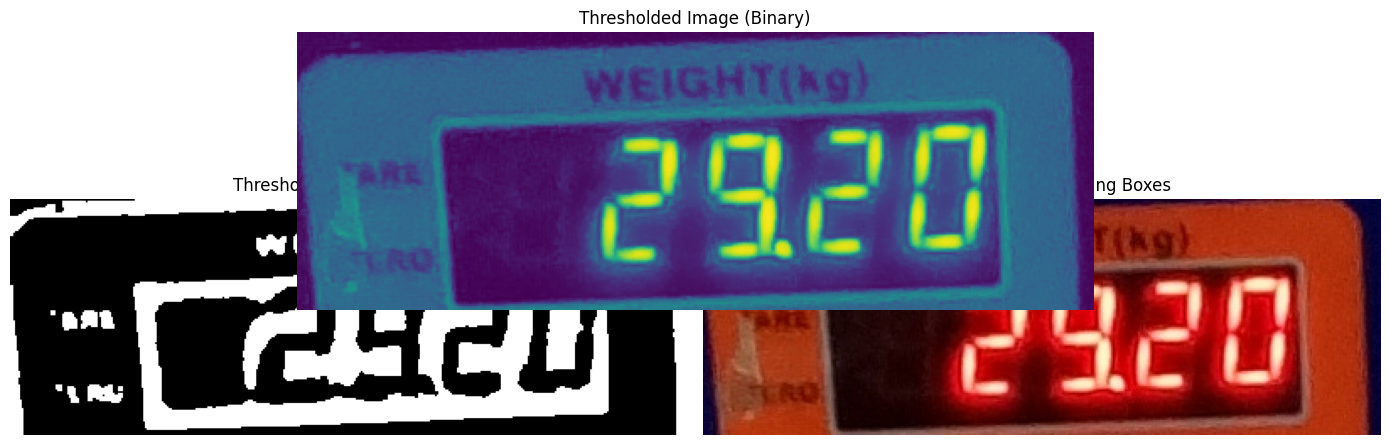

In [5]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# =========================================================
# 1️⃣ INPUT IMAGE
# =========================================================
image_path = r"IMG_20250909_194615_329.jpg"

# Read image
img = cv2.imread(image_path)
if img is None:
    raise SystemExit("❌ Image not found!")

# Convert to grayscale
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

# =========================================================
# 2️⃣ PREPROCESS (Enhance LED Digits)
# =========================================================
# Apply Gaussian blur to reduce noise
blur = cv2.GaussianBlur(gray, (5, 5), 0)

# Apply adaptive threshold for LED contrast
thresh = cv2.adaptiveThreshold(
    blur, 255, cv2.ADAPTIVE_THRESH_MEAN_C, cv2.THRESH_BINARY_INV, 35, 15
)

# Clean small noise
kernel = np.ones((3, 3), np.uint8)
thresh = cv2.morphologyEx(thresh, cv2.MORPH_OPEN, kernel)

# =========================================================
# 3️⃣ FIND CONTOURS (Possible Digits)
# =========================================================
contours, _ = cv2.findContours(thresh, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

digit_contours = []
for c in contours:
    x, y, w, h = cv2.boundingRect(c)
    aspect_ratio = h / float(w)
    if 1.2 < aspect_ratio < 5.0 and 15 < h < 200 and 5 < w < 100:
        digit_contours.append((x, y, w, h))

# Sort contours left to right (like reading digits)
digit_contours = sorted(digit_contours, key=lambda x: x[0])

print(f"✅ Found {len(digit_contours)} digit-like areas")

# =========================================================
# 4️⃣ VISUALIZE (Graph Instead of Saving)
# =========================================================
# Draw rectangles on original image
preview = img.copy()
for (x, y, w, h) in digit_contours:
    cv2.rectangle(preview, (x, y), (x + w, y + h), (0, 255, 0), 2)

# Convert BGR → RGB for matplotlib
preview_rgb = cv2.cvtColor(preview, cv2.COLOR_BGR2RGB)
thresh_rgb = cv2.cvtColor(thresh, cv2.COLOR_GRAY2RGB)

# =========================================================
# 5️⃣ SHOW RESULTS
# =========================================================
plt.figure(figsize=(14, 6))

plt.subplot(1, 2, 1)
plt.title("Thresholded Image (Binary)")
plt.imshow(thresh_rgb)
plt.axis("off")

plt.subplot(1, 2, 2)
plt.title("Detected Digit Bounding Boxes")
plt.imshow(preview_rgb)
plt.axis("off")

plt.subplot(2, 1, 1)
plt.title("Thresholded Image (Binary)")
plt.imshow(gray)
plt.axis("off")


plt.tight_layout()
plt.show()


✅ Adaptive Threshold: Found 6 digit-like areas
✅ Otsu Threshold: Found 0 digit-like areas
✅ Simple Threshold: Found 0 digit-like areas


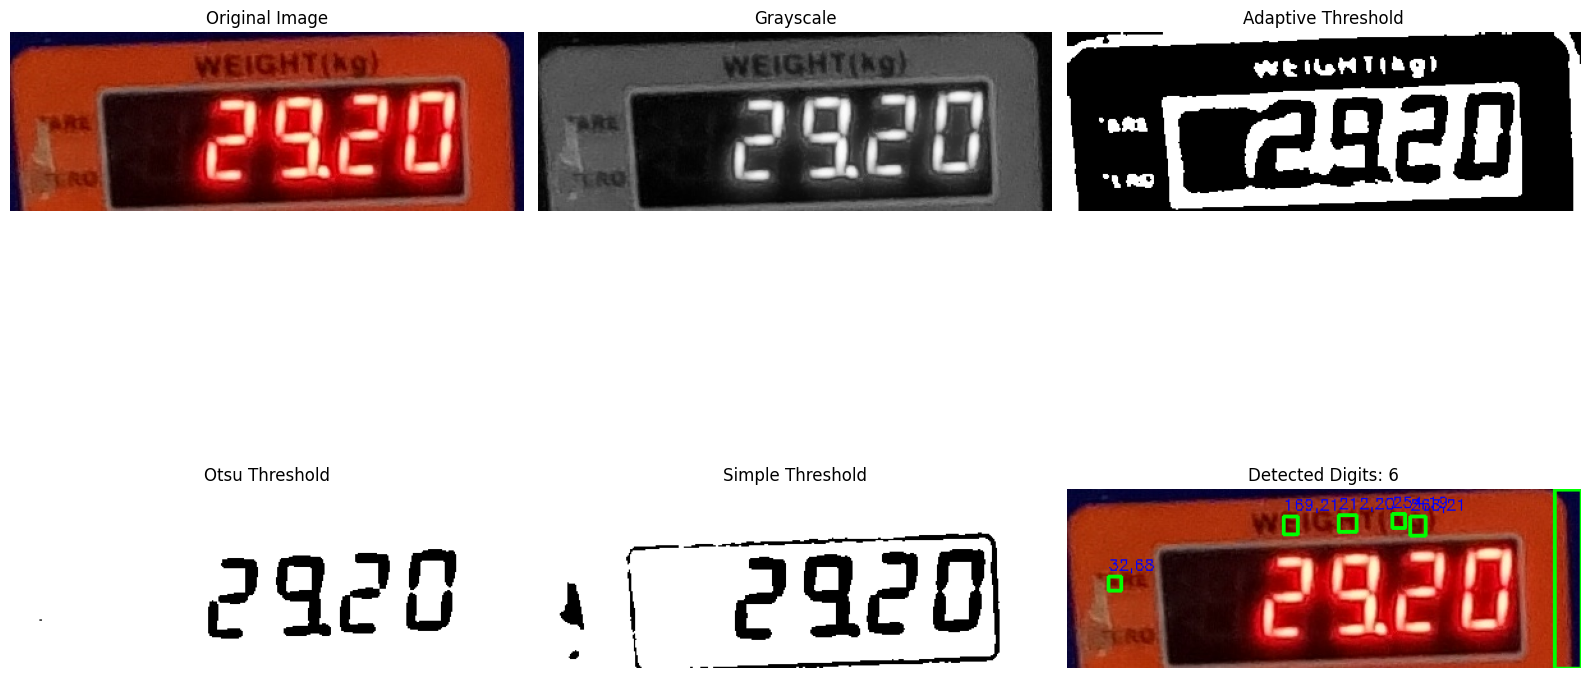


📊 Contour Analysis:
Contour 0: Position=(32,68), Size=(10x11), Area=110, Aspect Ratio=1.10
Contour 1: Position=(169,21), Size=(11x14), Area=154, Aspect Ratio=1.27
Contour 2: Position=(212,20), Size=(14x13), Area=182, Aspect Ratio=0.93
Contour 3: Position=(254,19), Size=(10x11), Area=110, Aspect Ratio=1.10
Contour 4: Position=(268,21), Size=(12x15), Area=180, Aspect Ratio=1.25
Contour 5: Position=(381,0), Size=(21x140), Area=2940, Aspect Ratio=6.67


In [7]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# =========================================================
# 1️⃣ INPUT IMAGE
# =========================================================
image_path = r"IMG_20250909_194615_329.jpg"

# Read image
img = cv2.imread(image_path)
if img is None:
    raise SystemExit("❌ Image not found!")

# Convert to grayscale
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

# =========================================================
# 2️⃣ IMPROVED PREPROCESSING
# =========================================================
# Apply Gaussian blur to reduce noise
blur = cv2.GaussianBlur(gray, (5, 5), 0)

# Try multiple thresholding methods
# Method 1: Adaptive threshold
thresh1 = cv2.adaptiveThreshold(
    blur, 255, cv2.ADAPTIVE_THRESH_MEAN_C, cv2.THRESH_BINARY_INV, 35, 15
)

# Method 2: Otsu's threshold
_, thresh2 = cv2.threshold(blur, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)

# Method 3: Simple threshold (adjust value as needed)
_, thresh3 = cv2.threshold(blur, 100, 255, cv2.THRESH_BINARY_INV)

# Clean noise
kernel = np.ones((2, 2), np.uint8)
thresh1 = cv2.morphologyEx(thresh1, cv2.MORPH_OPEN, kernel)
thresh2 = cv2.morphologyEx(thresh2, cv2.MORPH_OPEN, kernel)
thresh3 = cv2.morphologyEx(thresh3, cv2.MORPH_OPEN, kernel)

# =========================================================
# 3️⃣ IMPROVED CONTOUR DETECTION
# =========================================================
def find_digit_contours(thresh_img, method_name):
    contours, _ = cv2.findContours(thresh_img, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

    digit_contours = []
    for c in contours:
        x, y, w, h = cv2.boundingRect(c)
        area = cv2.contourArea(c)

        # More flexible criteria
        aspect_ratio = h / float(w) if w > 0 else 0
        area_ratio = area / (w * h) if (w * h) > 0 else 0

        # Relaxed constraints - adjust based on your image
        if (0.8 < aspect_ratio < 8.0 and  # Wider aspect ratio range
            10 < h < 300 and              # More flexible height
            5 < w < 150 and               # More flexible width
            area > 50):                   # Minimum area
            digit_contours.append((x, y, w, h))

    # Sort contours left to right
    digit_contours = sorted(digit_contours, key=lambda x: x[0])
    print(f"✅ {method_name}: Found {len(digit_contours)} digit-like areas")

    return digit_contours

# Try all thresholding methods
contours1 = find_digit_contours(thresh1, "Adaptive Threshold")
contours2 = find_digit_contours(thresh2, "Otsu Threshold")
contours3 = find_digit_contours(thresh3, "Simple Threshold")

# Use the method that found the most contours
all_contours = [contours1, contours2, contours3]
best_contours = max(all_contours, key=len)
digit_contours = best_contours

# =========================================================
# 4️⃣ DEBUG VISUALIZATION
# =========================================================
plt.figure(figsize=(16, 12))

# Original image
plt.subplot(2, 3, 1)
plt.title("Original Image")
plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.axis('off')

# Grayscale
plt.subplot(2, 3, 2)
plt.title("Grayscale")
plt.imshow(gray, cmap='gray')
plt.axis('off')

# Different thresholding methods
plt.subplot(2, 3, 3)
plt.title("Adaptive Threshold")
plt.imshow(thresh1, cmap='gray')
plt.axis('off')

plt.subplot(2, 3, 4)
plt.title("Otsu Threshold")
plt.imshow(thresh2, cmap='gray')
plt.axis('off')

plt.subplot(2, 3, 5)
plt.title("Simple Threshold")
plt.imshow(thresh3, cmap='gray')
plt.axis('off')

# Final result with bounding boxes
plt.subplot(2, 3, 6)
plt.title(f"Detected Digits: {len(digit_contours)}")
result_img = img.copy()
for (x, y, w, h) in digit_contours:
    cv2.rectangle(result_img, (x, y), (x + w, y + h), (0, 255, 0), 2)
    # Add contour index
    cv2.putText(result_img, f"{x},{y}", (x, y-5),
                cv2.FONT_HERSHEY_SIMPLEX, 0.4, (255, 0, 0), 1)
plt.imshow(cv2.cvtColor(result_img, cv2.COLOR_BGR2RGB))
plt.axis('off')

plt.tight_layout()
plt.show()

# =========================================================
# 5️⃣ CONTOUR ANALYSIS
# =========================================================
print(f"\n📊 Contour Analysis:")
for i, (x, y, w, h) in enumerate(digit_contours):
    area = w * h
    aspect_ratio = h / w
    print(f"Contour {i}: Position=({x},{y}), Size=({w}x{h}), "
          f"Area={area}, Aspect Ratio={aspect_ratio:.2f}")

✅ Found 0 digit-like areas


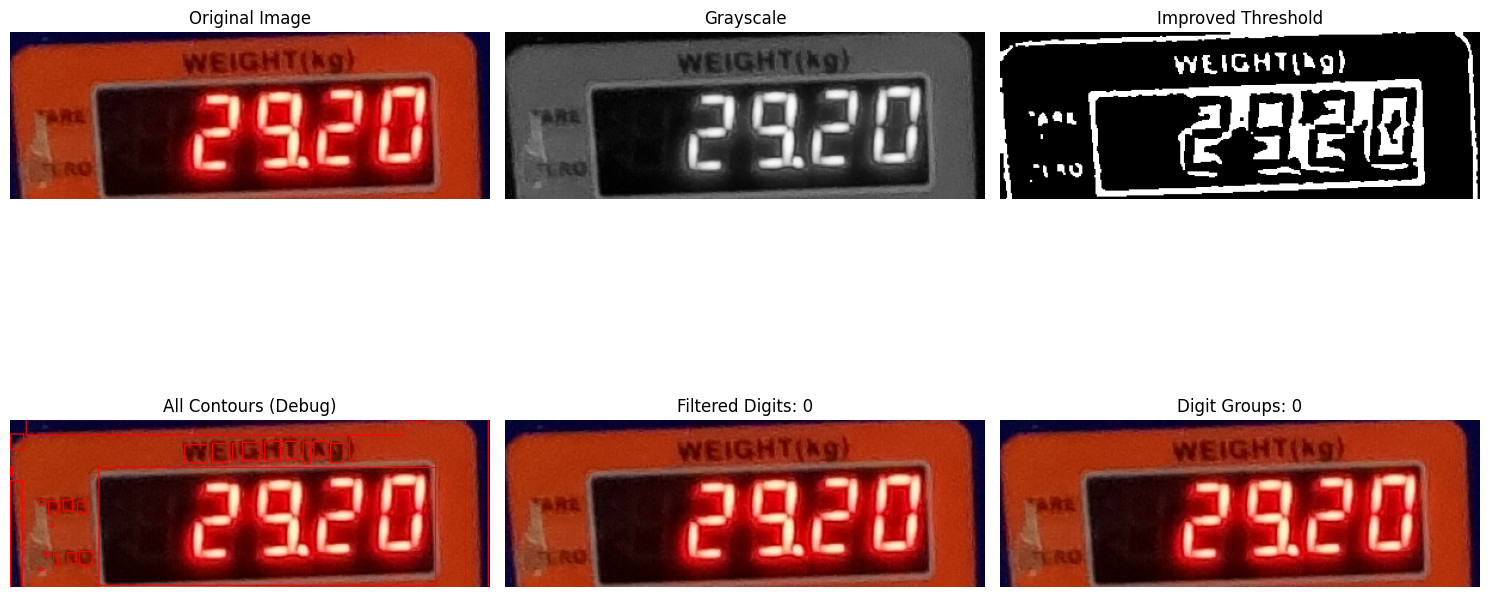


📊 Detailed Contour Analysis:
Total contours found: 28
Filtered digit contours: 0
Digit groups: 0

📏 Image Stats:
Threshold image size: (140, 402)
Non-zero pixels in threshold: 12913


In [8]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# =========================================================
# 1️⃣ INPUT IMAGE
# =========================================================
image_path = r"IMG_20250909_194615_329.jpg"

# Read image
img = cv2.imread(image_path)
if img is None:
    raise SystemExit("❌ Image not found!")

# Convert to grayscale
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

# =========================================================
# 2️⃣ FOCUSED PREPROCESSING FOR DIGITS
# =========================================================
# Apply Gaussian blur
blur = cv2.GaussianBlur(gray, (5, 5), 0)

# Use adaptive threshold - adjust parameters for better digit detection
thresh = cv2.adaptiveThreshold(
    blur, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C, cv2.THRESH_BINARY_INV, 25, 10
)

# Morphological operations to connect digit segments
kernel_close = np.ones((3, 3), np.uint8)
kernel_open = np.ones((2, 2), np.uint8)

# Close gaps within digits
thresh = cv2.morphologyEx(thresh, cv2.MORPH_CLOSE, kernel_close)
# Remove small noise
thresh = cv2.morphologyEx(thresh, cv2.MORPH_OPEN, kernel_open)

# =========================================================
# 3️⃣ IMPROVED CONTOUR DETECTION WITH BETTER FILTERING
# =========================================================
contours, _ = cv2.findContours(thresh, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

digit_contours = []
for c in contours:
    x, y, w, h = cv2.boundingRect(c)
    area = cv2.contourArea(c)
    bbox_area = w * h

    # Calculate solidity (area/bbox_area)
    solidity = area / bbox_area if bbox_area > 0 else 0

    # More specific criteria for 7-segment digits
    if (1.5 < h/w < 5.0 and        # Reasonable digit aspect ratio
        30 < h < 200 and            # Proper digit height
        15 < w < 80 and             # Proper digit width
        area > 200 and              # Minimum area to exclude noise
        solidity > 0.2):            # Should be reasonably solid
        digit_contours.append((x, y, w, h))

# Sort by x-coordinate (left to right)
digit_contours = sorted(digit_contours, key=lambda x: x[0])

print(f"✅ Found {len(digit_contours)} digit-like areas")

# =========================================================
# 4️⃣ GROUP DIGITS THAT ARE CLOSE TOGETHER (FOR MULTI-DIGIT DISPLAYS)
# =========================================================
def group_digits(contours, max_gap=30):
    if not contours:
        return []

    groups = []
    current_group = [contours[0]]

    for i in range(1, len(contours)):
        prev_x, prev_y, prev_w, prev_h = contours[i-1]
        curr_x, curr_y, curr_w, curr_h = contours[i]

        # Calculate gap between current and previous contour
        gap = curr_x - (prev_x + prev_w)

        if gap < max_gap:
            current_group.append(contours[i])
        else:
            groups.append(current_group)
            current_group = [contours[i]]

    if current_group:
        groups.append(current_group)

    return groups

digit_groups = group_digits(digit_contours)

# =========================================================
# 5️⃣ VISUALIZATION
# =========================================================
plt.figure(figsize=(15, 10))

# Original image
plt.subplot(2, 3, 1)
plt.title("Original Image")
plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.axis('off')

# Grayscale
plt.subplot(2, 3, 2)
plt.title("Grayscale")
plt.imshow(gray, cmap='gray')
plt.axis('off')

# Threshold
plt.subplot(2, 3, 3)
plt.title("Improved Threshold")
plt.imshow(thresh, cmap='gray')
plt.axis('off')

# All contours (for debugging)
plt.subplot(2, 3, 4)
plt.title("All Contours (Debug)")
debug_img = img.copy()
for c in contours:
    x, y, w, h = cv2.boundingRect(c)
    cv2.rectangle(debug_img, (x, y), (x + w, y + h), (0, 0, 255), 1)
plt.imshow(cv2.cvtColor(debug_img, cv2.COLOR_BGR2RGB))
plt.axis('off')

# Filtered digit contours
plt.subplot(2, 3, 5)
plt.title(f"Filtered Digits: {len(digit_contours)}")
result_img = img.copy()
for i, (x, y, w, h) in enumerate(digit_contours):
    cv2.rectangle(result_img, (x, y), (x + w, y + h), (0, 255, 0), 2)
    cv2.putText(result_img, str(i), (x, y-5),
                cv2.FONT_HERSHEY_SIMPLEX, 0.5, (255, 0, 0), 1)
plt.imshow(cv2.cvtColor(result_img, cv2.COLOR_BGR2RGB))
plt.axis('off')

# Digit groups
plt.subplot(2, 3, 6)
plt.title(f"Digit Groups: {len(digit_groups)}")
group_img = img.copy()
colors = [(0, 255, 0), (255, 0, 0), (0, 0, 255), (255, 255, 0)]
for i, group in enumerate(digit_groups):
    color = colors[i % len(colors)]
    for (x, y, w, h) in group:
        cv2.rectangle(group_img, (x, y), (x + w, y + h), color, 2)
plt.imshow(cv2.cvtColor(group_img, cv2.COLOR_BGR2RGB))
plt.axis('off')

plt.tight_layout()
plt.show()

# =========================================================
# 6️⃣ DETAILED ANALYSIS
# =========================================================
print(f"\n📊 Detailed Contour Analysis:")
print(f"Total contours found: {len(contours)}")
print(f"Filtered digit contours: {len(digit_contours)}")
print(f"Digit groups: {len(digit_groups)}")

for i, (x, y, w, h) in enumerate(digit_contours):
    area = cv2.contourArea([c for c in contours if cv2.boundingRect(c) == (x, y, w, h)][0])
    bbox_area = w * h
    solidity = area / bbox_area if bbox_area > 0 else 0
    aspect_ratio = h / w

    print(f"Digit {i}: Pos=({x},{y}), Size=({w}x{h}), "
          f"Area={area:.0f}, Aspect={aspect_ratio:.2f}, Solidity={solidity:.2f}")

# Show the threshold image properties
print(f"\n📏 Image Stats:")
print(f"Threshold image size: {thresh.shape}")
print(f"Non-zero pixels in threshold: {np.count_nonzero(thresh)}")

📍 Display ROI found: x=0, y=0, w=402, h=140
✅ Found 0 digit-like areas in display


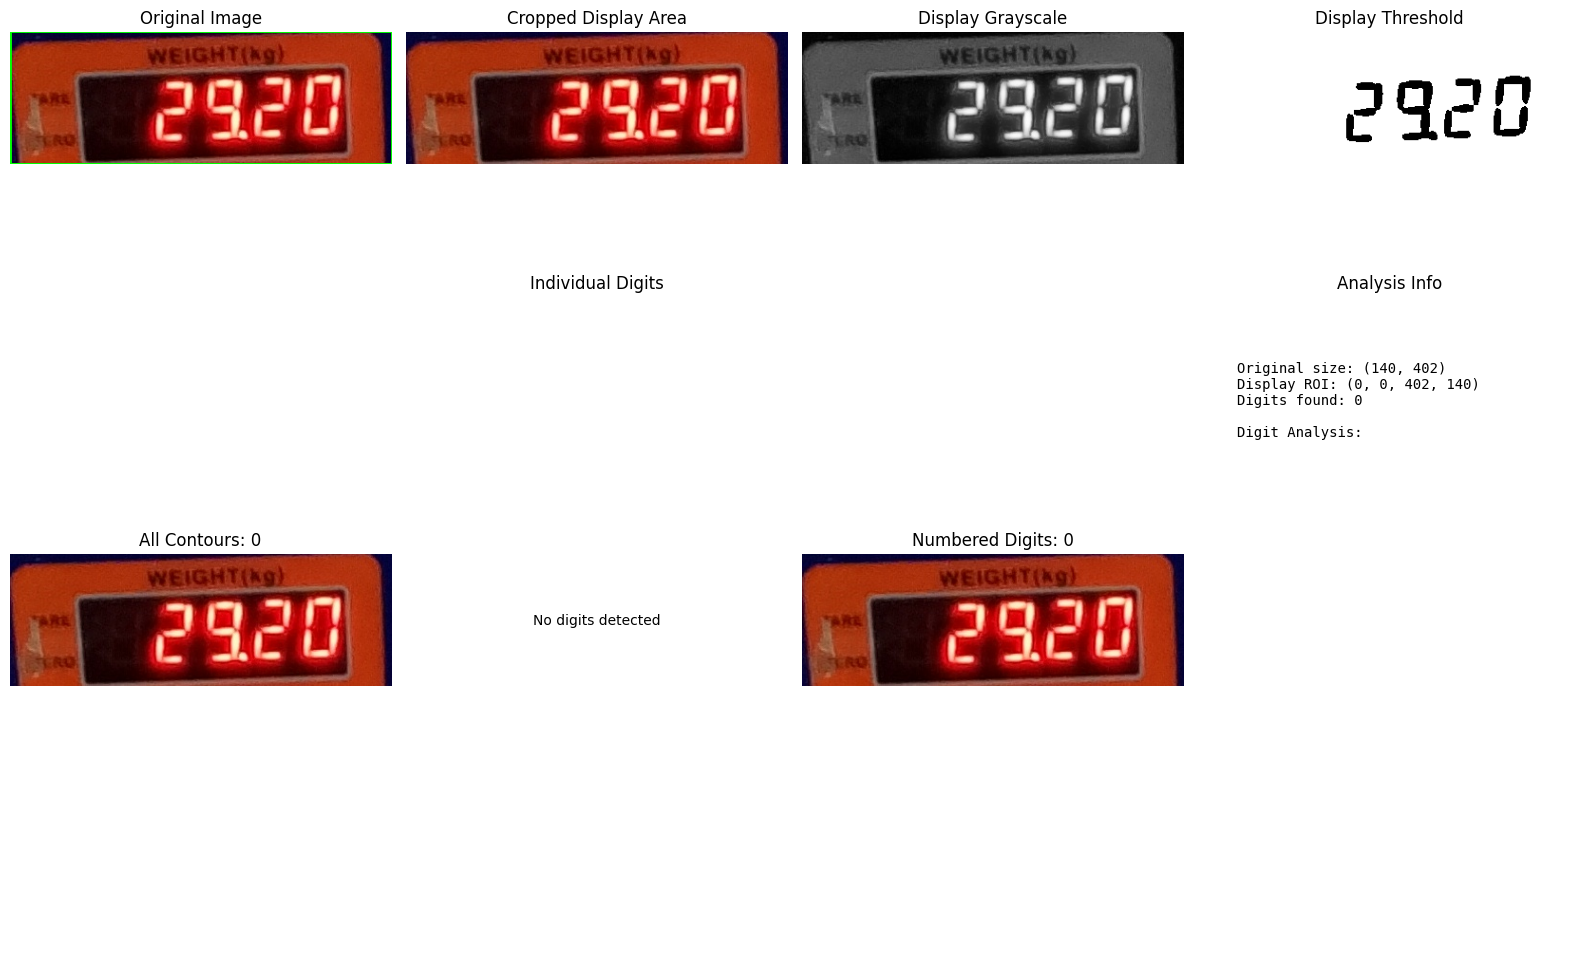


📊 DETAILED ANALYSIS:
Original image size: (140, 402)
Display ROI: (0, 0, 402, 140)
Display area size: (140, 402)
Digits detected: 0
Non-zero pixels in display threshold: 52122

🔍 DIGIT PROPERTIES:

💾 Cropped display saved as 'cropped_display.jpg'


In [9]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# =========================================================
# 1️⃣ INPUT IMAGE
# =========================================================
image_path = r"IMG_20250909_194615_329.jpg"

# Read image
img = cv2.imread(image_path)
if img is None:
    raise SystemExit("❌ Image not found!")

# Convert to grayscale
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

# =========================================================
# 2️⃣ DETECT AND CROP THE WEIGHT DISPLAY AREA
# =========================================================
def find_display_area(gray_img, original_img):
    # Apply Gaussian blur
    blur = cv2.GaussianBlur(gray_img, (5, 5), 0)

    # Use adaptive threshold to find bright areas (LCD display)
    thresh = cv2.adaptiveThreshold(
        blur, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C, cv2.THRESH_BINARY, 25, 10
    )

    # Find contours
    contours, _ = cv2.findContours(thresh, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

    # Look for large rectangular areas that could be the display
    display_contours = []
    for c in contours:
        x, y, w, h = cv2.boundingRect(c)
        area = w * h
        aspect_ratio = w / float(h)

        # Criteria for display area: large, rectangular, reasonable aspect ratio
        if (area > 5000 and  # Minimum area
            0.5 < aspect_ratio < 4.0 and  # Reasonable shape
            w > 100 and h > 50):  # Minimum dimensions
            display_contours.append((x, y, w, h, area))

    # Sort by area (largest first) and take the biggest one
    if display_contours:
        display_contours.sort(key=lambda x: x[4], reverse=True)
        x, y, w, h, area = display_contours[0]

        # Add some padding around the display
        padding_x = 10
        padding_y = 5
        x = max(0, x - padding_x)
        y = max(0, y - padding_y)
        w = min(gray_img.shape[1] - x, w + 2 * padding_x)
        h = min(gray_img.shape[0] - y, h + 2 * padding_y)

        return (x, y, w, h)

    return None

# Find the display area
display_roi = find_display_area(gray, img)

if display_roi:
    x, y, w, h = display_roi
    print(f"📍 Display ROI found: x={x}, y={y}, w={w}, h={h}")

    # Crop the image to the display area
    display_gray = gray[y:y+h, x:x+w]
    display_color = img[y:y+h, x:x+w]
else:
    print("❌ No display area found, using full image")
    display_gray = gray
    display_color = img

# =========================================================
# 3️⃣ PROCESS THE CROPPED DISPLAY AREA FOR DIGITS
# =========================================================
def process_digits(display_gray, display_color):
    # Apply Gaussian blur
    blur = cv2.GaussianBlur(display_gray, (3, 3), 0)

    # Use Otsu's threshold for better contrast
    _, thresh = cv2.threshold(blur, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)

    # Alternative: Adaptive threshold if Otsu doesn't work well
    if np.count_nonzero(thresh) < 100:  # If too few pixels detected
        thresh = cv2.adaptiveThreshold(
            blur, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C, cv2.THRESH_BINARY_INV, 15, 5
        )

    # Morphological operations to clean up the image
    kernel_close = np.ones((2, 2), np.uint8)
    kernel_open = np.ones((1, 1), np.uint8)

    # Close small gaps within digits
    thresh = cv2.morphologyEx(thresh, cv2.MORPH_CLOSE, kernel_close)
    # Remove small noise
    thresh = cv2.morphologyEx(thresh, cv2.MORPH_OPEN, kernel_open)

    return thresh

display_thresh = process_digits(display_gray, display_color)

# =========================================================
# 4️⃣ DETECT DIGITS IN THE CROPPED DISPLAY
# =========================================================
def detect_digits(thresh_img, display_color):
    contours, _ = cv2.findContours(thresh_img, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

    digit_contours = []
    for c in contours:
        x, y, w, h = cv2.boundingRect(c)
        area = cv2.contourArea(c)
        bbox_area = w * h
        solidity = area / bbox_area if bbox_area > 0 else 0
        aspect_ratio = h / float(w) if w > 0 else 0

        # Relaxed criteria for digits in cropped display
        if (1.0 < aspect_ratio < 6.0 and  # Wider aspect ratio range
            20 < h < 100 and              # Reasonable digit height in display
            8 < w < 50 and                # Reasonable digit width
            area > 50 and                 # Minimum area
            solidity > 0.1):              # Lower solidity threshold
            digit_contours.append((x, y, w, h, area, aspect_ratio))

    # Sort by x-coordinate (left to right)
    digit_contours.sort(key=lambda x: x[0])

    return digit_contours

digit_contours = detect_digits(display_thresh, display_color)
print(f"✅ Found {len(digit_contours)} digit-like areas in display")

# =========================================================
# 5️⃣ GROUP DIGITS AND EXTRACT ROI
# =========================================================
def extract_digit_regions(digit_contours, display_thresh, display_color):
    digit_regions = []

    for i, (x, y, w, h, area, aspect_ratio) in enumerate(digit_contours):
        # Extract the digit region from threshold
        digit_img = display_thresh[y:y+h, x:x+w]

        # Add some padding around the digit
        pad = 2
        digit_padded = cv2.copyMakeBorder(digit_img, pad, pad, pad, pad,
                                         cv2.BORDER_CONSTANT, value=0)

        digit_regions.append({
            'img': digit_padded,
            'bbox': (x, y, w, h),
            'area': area,
            'aspect_ratio': aspect_ratio
        })

    return digit_regions

digit_regions = extract_digit_regions(digit_contours, display_thresh, display_color)

# =========================================================
# 6️⃣ VISUALIZATION
# =========================================================
plt.figure(figsize=(16, 12))

# Original image with display ROI
plt.subplot(2, 4, 1)
plt.title("Original Image")
original_display = img.copy()
if display_roi:
    x, y, w, h = display_roi
    cv2.rectangle(original_display, (x, y), (x + w, y + h), (0, 255, 0), 2)
plt.imshow(cv2.cvtColor(original_display, cv2.COLOR_BGR2RGB))
plt.axis('off')

# Cropped display area
plt.subplot(2, 4, 2)
plt.title("Cropped Display Area")
plt.imshow(cv2.cvtColor(display_color, cv2.COLOR_BGR2RGB))
plt.axis('off')

# Display area grayscale
plt.subplot(2, 4, 3)
plt.title("Display Grayscale")
plt.imshow(display_gray, cmap='gray')
plt.axis('off')

# Display threshold
plt.subplot(2, 4, 4)
plt.title("Display Threshold")
plt.imshow(display_thresh, cmap='gray')
plt.axis('off')

# All contours in display
plt.subplot(2, 4, 5)
plt.title(f"All Contours: {len(digit_contours)}")
contour_img = display_color.copy()
for (x, y, w, h, area, aspect_ratio) in digit_contours:
    cv2.rectangle(contour_img, (x, y), (x + w, y + h), (0, 255, 0), 2)
plt.imshow(cv2.cvtColor(contour_img, cv2.COLOR_BGR2RGB))
plt.axis('off')

# Individual digits
plt.subplot(2, 4, 6)
plt.title("Individual Digits")
# Create a montage of detected digits
if digit_regions:
    digit_montage = np.hstack([region['img'] for region in digit_regions[:8]])
    plt.imshow(digit_montage, cmap='gray')
else:
    plt.text(0.5, 0.5, "No digits detected", ha='center', va='center',
             transform=plt.gca().transAxes)
plt.axis('off')

# Final result with numbered digits
plt.subplot(2, 4, 7)
plt.title(f"Numbered Digits: {len(digit_contours)}")
result_img = display_color.copy()
for i, (x, y, w, h, area, aspect_ratio) in enumerate(digit_contours):
    cv2.rectangle(result_img, (x, y), (x + w, y + h), (0, 255, 0), 2)
    cv2.putText(result_img, str(i), (x, y-5),
                cv2.FONT_HERSHEY_SIMPLEX, 0.5, (255, 0, 0), 1)
plt.imshow(cv2.cvtColor(result_img, cv2.COLOR_BGR2RGB))
plt.axis('off')

# Display analysis info
plt.subplot(2, 4, 8)
plt.title("Analysis Info")
info_text = [
    f"Original size: {gray.shape}",
    f"Display ROI: {display_roi}" if display_roi else "Display ROI: Not found",
    f"Digits found: {len(digit_contours)}",
    "",
    "Digit Analysis:"
]

for i, region in enumerate(digit_regions):
    x, y, w, h = region['bbox']
    info_text.append(f"Digit {i}: {w}x{h} (AR:{region['aspect_ratio']:.1f})")

plt.axis('off')
plt.text(0.1, 0.9, "\n".join(info_text), transform=plt.gca().transAxes,
         fontfamily='monospace', verticalalignment='top')

plt.tight_layout()
plt.show()

# =========================================================
# 7️⃣ DETAILED ANALYSIS
# =========================================================
print(f"\n📊 DETAILED ANALYSIS:")
print(f"Original image size: {gray.shape}")
print(f"Display ROI: {display_roi}")
print(f"Display area size: {display_gray.shape}")
print(f"Digits detected: {len(digit_contours)}")
print(f"Non-zero pixels in display threshold: {np.count_nonzero(display_thresh)}")

print(f"\n🔍 DIGIT PROPERTIES:")
for i, (x, y, w, h, area, aspect_ratio) in enumerate(digit_contours):
    print(f"  Digit {i}: Position=({x},{y}), Size=({w}x{h}), "
          f"Area={area:.0f}, Aspect Ratio={aspect_ratio:.2f}")

# Save the cropped display for further processing
if display_roi:
    cv2.imwrite('cropped_display.jpg', display_color)
    print(f"\n💾 Cropped display saved as 'cropped_display.jpg'")

Progress: |██████████████████████████████████████████████████| 100.0% Complete

Progress: |██████████████████████████████████████████████████| 100.0% Complete

/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py:666: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  warnings.warn(warn_msg)


✅ Detected text: weiGhT(A9)TnTeu2920


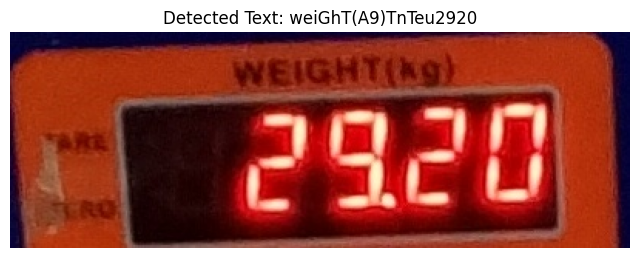

In [12]:
import easyocr
import cv2
import matplotlib.pyplot as plt

# Load the cropped display image
try:
    cropped_display = cv2.imread('cropped_display.jpg')
    if cropped_display is None:
        raise FileNotFoundError("cropped_display.jpg not found.")

    # Convert to grayscale (easyocr can work on color, but grayscale is often sufficient)
    cropped_gray = cv2.cvtColor(cropped_display, cv2.COLOR_BGR2GRAY)

    # Initialize EasyOCR reader
    reader = easyocr.Reader(['en'])

    # Perform OCR on the cropped grayscale image
    result = reader.readtext(cropped_gray, detail=0) # detail=0 gives just the text

    # Join the detected text
    detected_text = ''.join(result)

    print("✅ Detected text:", detected_text)

    # Optional: Display the cropped image with the detected text
    plt.figure(figsize=(8, 4))
    plt.imshow(cv2.cvtColor(cropped_display, cv2.COLOR_BGR2RGB))
    plt.title(f"Detected Text: {detected_text}")
    plt.axis('off')
    plt.show()

except FileNotFoundError as e:
    print(f"❌ Error: {e}")
except Exception as e:
    print(f"❌ An error occurred during OCR: {e}")

/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py:666: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  warnings.warn(warn_msg)


✅ OCR Result (detailed): [([[np.int32(140), np.int32(10)], [np.int32(296), np.int32(10)], [np.int32(296), np.int32(42)], [np.int32(140), np.int32(42)]], 'weiGhT(A9)', np.float64(0.1044223331651997)), ([[np.int32(27), np.int32(63)], [np.int32(65), np.int32(63)], [np.int32(65), np.int32(79)], [np.int32(27), np.int32(79)]], 'Tn', np.float64(0.023440648790180558)), ([[np.int32(29), np.int32(107)], [np.int32(73), np.int32(107)], [np.int32(73), np.int32(123)], [np.int32(29), np.int32(123)]], 'Teu', np.float64(0.13461498667894028)), ([[np.int32(139), np.int32(32)], [np.int32(364), np.int32(32)], [np.int32(364), np.int32(133)], [np.int32(139), np.int32(133)]], '2920', np.float64(0.9819051623344421))]
✅ Detected text (joined): weiGhT(A9)TnTeu2920


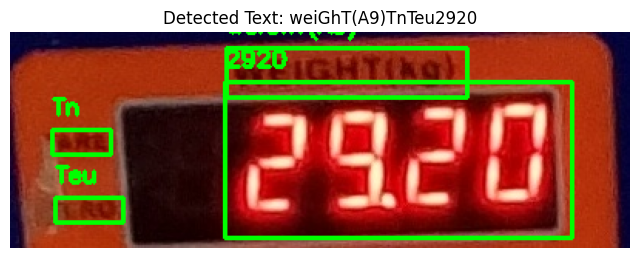

In [21]:
import easyocr
import cv2
import matplotlib.pyplot as plt
import re

# Load the cropped display image
try:
    cropped_display = cv2.imread('cropped_display.jpg')
    if cropped_display is None:
        raise FileNotFoundError("cropped_display.jpg not found.")

    # Convert to grayscale (easyocr can work on color, but grayscale is often sufficient)
    cropped_gray = cv2.cvtColor(cropped_display, cv2.COLOR_BGR2GRAY)

    # Initialize EasyOCR reader
    reader = easyocr.Reader(['en'])

    # Perform OCR on the cropped grayscale image, get detailed results
    result = reader.readtext(cropped_gray, detail=1)

    print("✅ OCR Result (detailed):", result)

    # Extract detected text for display
    detected_text = ''.join([res[1] for res in result])
    print("✅ Detected text (joined):", detected_text)


    # Optional: Display the cropped image with the detected text and bounding boxes
    plt.figure(figsize=(8, 4))
    plt.imshow(cv2.cvtColor(cropped_display, cv2.COLOR_BGR2RGB))
    plt.title(f"Detected Text: {detected_text}")
    plt.axis('off')

    # Draw bounding boxes
    for (bbox, text, prob) in result:
        (tl, tr, br, bl) = bbox
        tl = (int(tl[0]), int(tl[1]))
        tr = (int(tr[0]), int(tr[1]))
        br = (int(br[0]), int(br[1]))
        bl = (int(bl[0]), int(bl[1]))
        cv2.rectangle(cropped_display, tl, br, (0, 255, 0), 2)
        cv2.putText(cropped_display, text, (tl[0], tl[1] - 10),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.5, (0, 255, 0), 2)

    plt.imshow(cv2.cvtColor(cropped_display, cv2.COLOR_BGR2RGB))
    plt.show()


except FileNotFoundError as e:
    print(f"❌ Error: {e}")
except Exception as e:
    print(f"❌ An error occurred during OCR: {e}")

In [22]:
import re

# The detected text from the previous step (will be updated after rerunning the OCR cell)
# Example from previous run: detected_text = "weiGhT(A9)TnTeu2920"

# Use regular expression to find the last sequence of digits, which is likely the weight
weight_match = re.search(r'\d+(\.\d+)?$', detected_text)

extracted_weight = ""
if weight_match:
    extracted_weight = weight_match.group(0)
    print(f"✅ Extracted weight: {extracted_weight}")
else:
    print("❌ No numerical weight found at the end of the detected text.")

# You can now use the extracted_weight variable
# For example, convert it to a float:
try:
    weight_value = float(extracted_weight)
    print(f"✅ Weight value as float: {weight_value}")
except ValueError:
    print("❌ Could not convert extracted weight to a float.")

✅ Extracted weight: 2920
✅ Weight value as float: 2920.0


In [11]:
!pip install easyocr

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.9/2.9 MB 28.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 180.7/180.7 kB 12.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 963.8/963.8 kB 47.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 292.1/292.1 kB 18.7 MB/s eta 0:00:00


🔧 Using manual crop: x=100, y=40, w=250, h=180
📍 Cropped display size: (67, 209)
📊 Threshold pixel counts - Otsu: 11742, Adaptive: 5560, Simple: 11809
✅ Using Simple thresholding
✅ Found 3 digit-like areas in cropped display


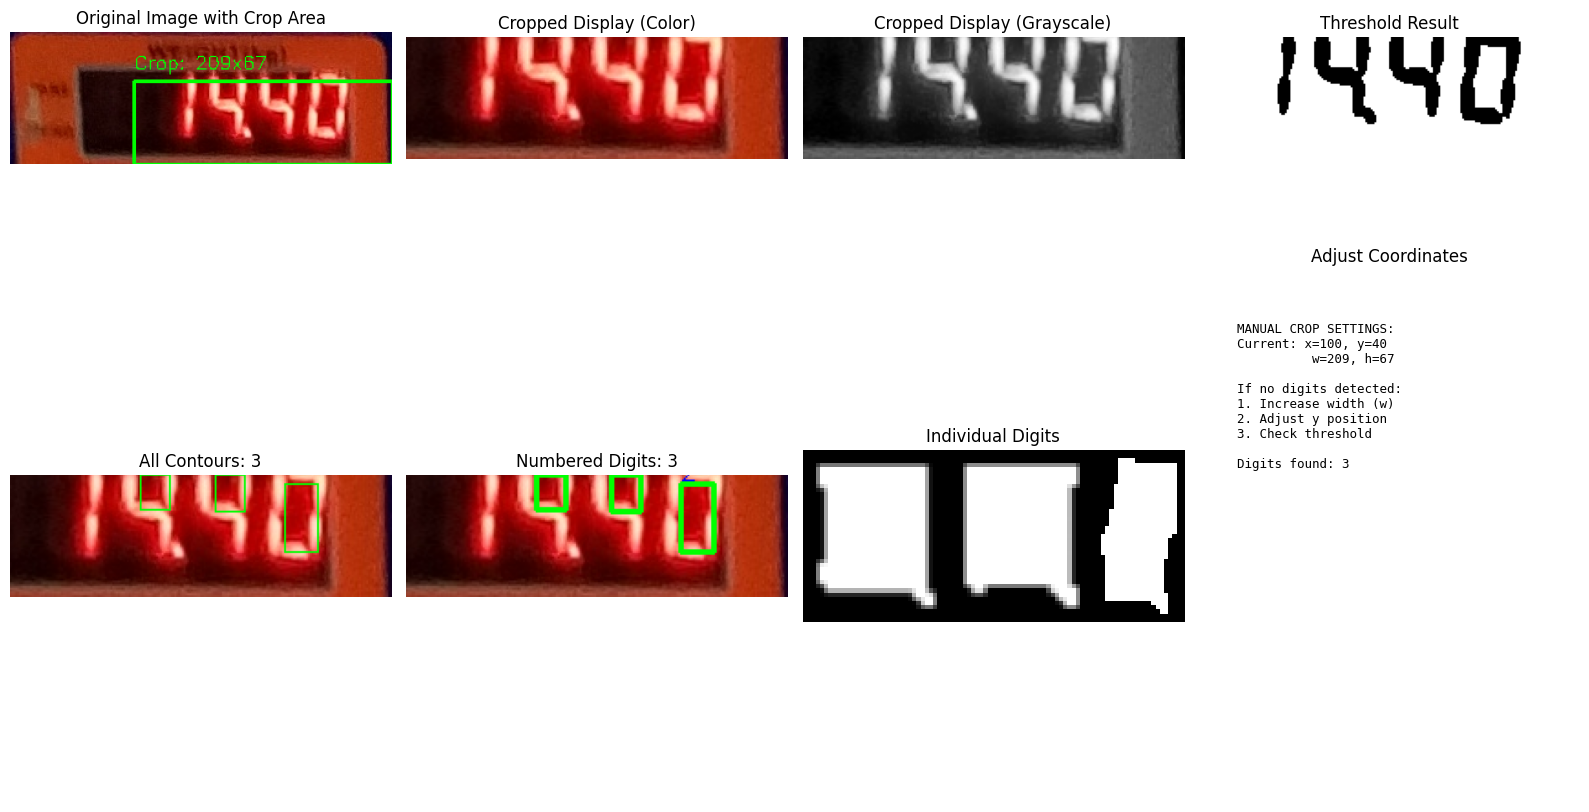


📊 DETAILED ANALYSIS:
Original image size: (107, 309)
Display ROI: x=100, y=40, w=209, h=67
Cropped display size: (67, 209)
Digits detected: 3

🔍 DIGIT PROPERTIES:
  Digit 0: Pos=(71,0), Size=(16x19), Area=217, Aspect=1.19
  Digit 1: Pos=(112,0), Size=(16x20), Area=236, Aspect=1.25
  Digit 2: Pos=(150,5), Size=(18x37), Area=460, Aspect=2.06

💡 COORDINATE SUGGESTIONS for image size 309x107:
   Try these presets in the manual_crop_display function:
   1. Top-right: x=59, y=10, w=200, h=50
   2. Center-top: x=54, y=10, w=200, h=50
   3. Wide area: x=4, y=5, w=300, h=60


In [8]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# =========================================================
# 1️⃣ INPUT IMAGE
# =========================================================
image_path = r"IMG_20250909_194902_301.jpg"

# Read image
img = cv2.imread(image_path)
if img is None:
    raise SystemExit("❌ Image not found!")

# Convert to grayscale
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

# =========================================================
# 2️⃣ MANUAL CROPPING - ADJUST THESE COORDINATES!
# =========================================================
def manual_crop_display(img, gray):
    """
    MANUALLY adjust these coordinates to crop the weight display area
    Format: (x, y, width, height)

    For your image showing "2920", you'll need to adjust these values.
    Look at your image and estimate where the digits are located.
    """

    # ⚠️ ADJUST THESE VALUES BASED ON YOUR IMAGE ⚠️
    # Example: if digits are in top-right area, use something like:
    x = 100    # Left position
    y = 40     # Top position
    w = 250    # Width of display area
    h = 180     # Height of display area

    # Alternative coordinates you can try:
    # x, y, w, h = 200, 15, 180, 40   # Try this if above doesn't work
    # x, y, w, h = 180, 5, 220, 60    # Or this

    print(f"🔧 Using manual crop: x={x}, y={y}, w={w}, h={h}")

    # Ensure coordinates are within image bounds
    x = max(0, x)
    y = max(0, y)
    w = min(img.shape[1] - x, w)
    h = min(img.shape[0] - y, h)

    display_gray = gray[y:y+h, x:x+w]
    display_color = img[y:y+h, x:x+w]

    return display_gray, display_color, (x, y, w, h)

# Apply manual cropping
display_gray, display_color, display_roi = manual_crop_display(img, gray)
x, y, w, h = display_roi

print(f"📍 Cropped display size: {display_gray.shape}")

# =========================================================
# 3️⃣ PROCESS THE CROPPED DISPLAY AREA
# =========================================================
def process_display_for_digits(display_gray):
    # Apply Gaussian blur
    blur = cv2.GaussianBlur(display_gray, (3, 3), 0)

    # Try multiple thresholding methods
    # Method 1: Otsu's threshold
    _, thresh_otsu = cv2.threshold(blur, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)

    # Method 2: Adaptive threshold
    thresh_adapt = cv2.adaptiveThreshold(
        blur, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C, cv2.THRESH_BINARY_INV, 11, 2
    )

    # Method 3: Simple threshold (adjust this value)
    _, thresh_simple = cv2.threshold(blur, 120, 255, cv2.THRESH_BINARY_INV)

    # Choose the best threshold method
    otsu_pixels = np.count_nonzero(thresh_otsu)
    adapt_pixels = np.count_nonzero(thresh_adapt)
    simple_pixels = np.count_nonzero(thresh_simple)

    print(f"📊 Threshold pixel counts - Otsu: {otsu_pixels}, Adaptive: {adapt_pixels}, Simple: {simple_pixels}")

    # Use the one with reasonable number of pixels (not too many, not too few)
    if 100 < otsu_pixels < 2000:
        thresh = thresh_otsu
        method = "Otsu"
    elif 100 < adapt_pixels < 2000:
        thresh = thresh_adapt
        method = "Adaptive"
    else:
        thresh = thresh_simple
        method = "Simple"

    print(f"✅ Using {method} thresholding")

    # Clean up the image
    kernel = np.ones((2, 2), np.uint8)
    thresh = cv2.morphologyEx(thresh, cv2.MORPH_OPEN, kernel)  # Remove noise
    thresh = cv2.morphologyEx(thresh, cv2.MORPH_CLOSE, kernel) # Connect digit parts

    return thresh

display_thresh = process_display_for_digits(display_gray)

# =========================================================
# 4️⃣ DETECT DIGITS IN CROPPED DISPLAY
# =========================================================
def detect_digits_in_display(thresh_img):
    contours, _ = cv2.findContours(thresh_img, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

    digit_contours = []
    for c in contours:
        x, y, w, h = cv2.boundingRect(c)
        area = cv2.contourArea(c)

        # Relaxed criteria for digits in display
        aspect_ratio = h / float(w) if w > 0 else 0

        # Adjust these criteria based on what you see
        if (0.8 < aspect_ratio < 8.0 and  # Wide aspect ratio range
            15 < h < 80 and               # Reasonable height for display digits
            5 < w < 40 and                # Reasonable width
            area > 30):                   # Minimum area
            digit_contours.append((x, y, w, h, area, aspect_ratio))

    # Sort left to right
    digit_contours.sort(key=lambda x: x[0])

    return digit_contours

digit_contours = detect_digits_in_display(display_thresh)
print(f"✅ Found {len(digit_contours)} digit-like areas in cropped display")

# =========================================================
# 5️⃣ VISUALIZATION
# =========================================================
plt.figure(figsize=(16, 10))

# 1. Original image with crop area
plt.subplot(2, 4, 1)
plt.title("Original Image with Crop Area")
original_with_roi = img.copy()
cv2.rectangle(original_with_roi, (x, y), (x + w, y + h), (0, 255, 0), 2)
cv2.putText(original_with_roi, f"Crop: {w}x{h}", (x, y-10),
            cv2.FONT_HERSHEY_SIMPLEX, 0.5, (0, 255, 0), 1)
plt.imshow(cv2.cvtColor(original_with_roi, cv2.COLOR_BGR2RGB))
plt.axis('off')

# 2. Cropped display area (color)
plt.subplot(2, 4, 2)
plt.title("Cropped Display (Color)")
plt.imshow(cv2.cvtColor(display_color, cv2.COLOR_BGR2RGB))
plt.axis('off')

# 3. Cropped display area (grayscale)
plt.subplot(2, 4, 3)
plt.title("Cropped Display (Grayscale)")
plt.imshow(display_gray, cmap='gray')
plt.axis('off')

# 4. Threshold result
plt.subplot(2, 4, 4)
plt.title("Threshold Result")
plt.imshow(display_thresh, cmap='gray')
plt.axis('off')

# 5. All contours in display
plt.subplot(2, 4, 5)
plt.title(f"All Contours: {len(digit_contours)}")
contour_img = display_color.copy()
for (x_d, y_d, w_d, h_d, area, ar) in digit_contours:
    cv2.rectangle(contour_img, (x_d, y_d), (x_d + w_d, y_d + h_d), (0, 255, 0), 1)
plt.imshow(cv2.cvtColor(contour_img, cv2.COLOR_BGR2RGB))
plt.axis('off')

# 6. Numbered digits
plt.subplot(2, 4, 6)
plt.title(f"Numbered Digits: {len(digit_contours)}")
numbered_img = display_color.copy()
for i, (x_d, y_d, w_d, h_d, area, ar) in enumerate(digit_contours):
    cv2.rectangle(numbered_img, (x_d, y_d), (x_d + w_d, y_d + h_d), (0, 255, 0), 2)
    cv2.putText(numbered_img, str(i), (x_d, y_d-2),
                cv2.FONT_HERSHEY_SIMPLEX, 0.4, (255, 0, 0), 1)
plt.imshow(cv2.cvtColor(numbered_img, cv2.COLOR_BGR2RGB))
plt.axis('off')

# 7. Individual digit images
plt.subplot(2, 4, 7)
plt.title("Individual Digits")
if digit_contours:
    # Extract each digit
    digit_images = []
    for (x_d, y_d, w_d, h_d, area, ar) in digit_contours:
        digit_img = display_thresh[y_d:y_d+h_d, x_d:x_d+w_d]
        # Add padding
        digit_padded = cv2.copyMakeBorder(digit_img, 2, 2, 2, 2,
                                        cv2.BORDER_CONSTANT, value=0)
        digit_images.append(digit_padded)

    # Create montage
    if digit_images:
        # Resize to same height for display
        max_height = max(img.shape[0] for img in digit_images)
        resized_digits = []
        for digit_img in digit_images:
            scale = max_height / digit_img.shape[0]
            new_width = int(digit_img.shape[1] * scale)
            resized = cv2.resize(digit_img, (new_width, max_height))
            resized_digits.append(resized)

        montage = np.hstack(resized_digits)
        plt.imshow(montage, cmap='gray')
else:
    plt.text(0.5, 0.5, "No digits\ndetected", ha='center', va='center',
             transform=plt.gca().transAxes, fontsize=12)
plt.axis('off')

# 8. Coordinate helper
plt.subplot(2, 4, 8)
plt.title("Adjust Coordinates")
help_text = [
    "MANUAL CROP SETTINGS:",
    f"Current: x={x}, y={y}",
    f"          w={w}, h={h}",
    "",
    "If no digits detected:",
    "1. Increase width (w)",
    "2. Adjust y position",
    "3. Check threshold",
    "",
    f"Digits found: {len(digit_contours)}"
]
plt.axis('off')
plt.text(0.1, 0.9, "\n".join(help_text), transform=plt.gca().transAxes,
         fontfamily='monospace', fontsize=9, verticalalignment='top')

plt.tight_layout()
plt.show()

# =========================================================
# 6️⃣ DETAILED ANALYSIS
# =========================================================
print(f"\n📊 DETAILED ANALYSIS:")
print(f"Original image size: {gray.shape}")
print(f"Display ROI: x={x}, y={y}, w={w}, h={h}")
print(f"Cropped display size: {display_gray.shape}")
print(f"Digits detected: {len(digit_contours)}")

if digit_contours:
    print(f"\n🔍 DIGIT PROPERTIES:")
    for i, (x_d, y_d, w_d, h_d, area, aspect_ratio) in enumerate(digit_contours):
        print(f"  Digit {i}: Pos=({x_d},{y_d}), Size=({w_d}x{h_d}), "
              f"Area={area:.0f}, Aspect={aspect_ratio:.2f}")
else:
    print(f"\n❌ NO DIGITS DETECTED - Try adjusting manual crop coordinates!")
    print("   Suggested adjustments:")
    print("   - Increase width (w) to capture more area")
    print("   - Adjust y position up/down")
    print("   - Try different x starting position")

# =========================================================
# 7️⃣ COORDINATE ADJUSTMENT HELPER
# =========================================================
def suggest_coordinates(img_shape):
    height, width = img_shape
    print(f"\n💡 COORDINATE SUGGESTIONS for image size {width}x{height}:")
    print("   Try these presets in the manual_crop_display function:")
    print(f"   1. Top-right: x={width-250}, y=10, w=200, h=50")
    print(f"   2. Center-top: x={width//2-100}, y=10, w=200, h=50")
    print(f"   3. Wide area: x={width//2-150}, y=5, w=300, h=60")

suggest_coordinates(gray.shape)